# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

In [34]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [35]:
%cd /content/drive/My\ Drive/ICT 110 - AppDev

/content/drive/My Drive/ICT 110 - AppDev


In [36]:
!pwd

/content/drive/My Drive/ICT 110 - AppDev


---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.


**ANSWER**: The objective is to predict whether a breast mass is malignant or benign using 30 numeric features derived from fine-needle aspirate (FNA) cell nucleus images. This task is a supervised binary classification problem. A false negative error—misidentifying a malignant tumor as benign—presents a much higher cost due to the potential for untreated cancer progression and critical risks to patient health. Model performance will be evaluated based on overall cross-validation accuracy alongside a high recall rate for the malignant class to ensure false negatives are minimized.

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [4]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.feature_selection import RFE, SelectKBest, f_classif
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    make_scorer,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_score,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Classifier & Ensemble imports
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import (
    AdaBoostClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    VotingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).

> *Using your own data?* Only this cell changes. For an ARFF file use `scipy.io.arff.loadarff`, and keep the rest of the workbook as is.

> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [10]:
# TODO: load the dataset and copy its DataFrame into df
...
print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [11]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows
print("Shape:", df.shape)
print("\nDtype counts:\n", df.dtypes.value_counts())
display(df.head())# Print the shape, the counts of each dtype, and show the first 5 rows
print("Shape:", df.shape)
print("\nDtype counts:\n", df.dtypes.value_counts())
display(df.head())

Shape: (569, 31)

Dtype counts:
 float64    30
int64       1
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Shape: (569, 31)

Dtype counts:
 float64    30
int64       1
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [12]:
# TODO: class counts and percentages
counts = df["target"].value_counts()
proportions = df["target"].value_counts(normalize=True) * 100

summary_df = pd.DataFrame({"Count": counts, "Percentage (%)": proportions})
print(summary_df)

        Count  Percentage (%)
target                       
1         357       62.741652
0         212       37.258348


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [13]:
# TODO: describe().T, then the 10 largest skewness values
print("Summary Statistics:")
display(df.describe().T)

skewness = df.drop(columns=["target"]).skew().abs().sort_values(ascending=False)
print("\nTop 10 most skewed features:")
print(skewness.head(10))

Summary Statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



Top 10 most skewed features:
area error                 5.447186
concavity error            5.110463
fractal dimension error    3.923969
perimeter error            3.443615
radius error               3.088612
smoothness error           2.314450
symmetry error             2.195133
compactness error          1.902221
worst area                 1.859373
worst fractal dimension    1.662579
dtype: float64


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [14]:
# TODO: correlation with target, sorted
corr_with_target = df.corr()["target"].drop("target").sort_values()

print("Top 5 most negative correlations with target:")
print(corr_with_target.head(5))

print("\nTop 5 most positive correlations with target:")
print(corr_with_target.tail(5))

Top 5 most negative correlations with target:
worst concave points   -0.793566
worst perimeter        -0.782914
mean concave points    -0.776614
worst radius           -0.776454
mean perimeter         -0.742636
Name: target, dtype: float64

Top 5 most positive correlations with target:
fractal dimension error   -0.077972
symmetry error             0.006522
texture error              0.008303
mean fractal dimension     0.012838
smoothness error           0.067016
Name: target, dtype: float64


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

**ANSWER:**
The ~63% benign to 37% malignant class split shows a slight class imbalance. Because of this, accuracy alone can be misleading, making metrics like recall, precision, and ROC-AUC necessary to track performance on the minority (malignant) class.

High positive skewness across several features indicates long right tails and extreme values. Scaling or transforming these features is necessary to prevent distance- and gradient-based algorithms (like KNN, SVM, and Logistic Regression) from being dominated by large feature magnitudes.

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

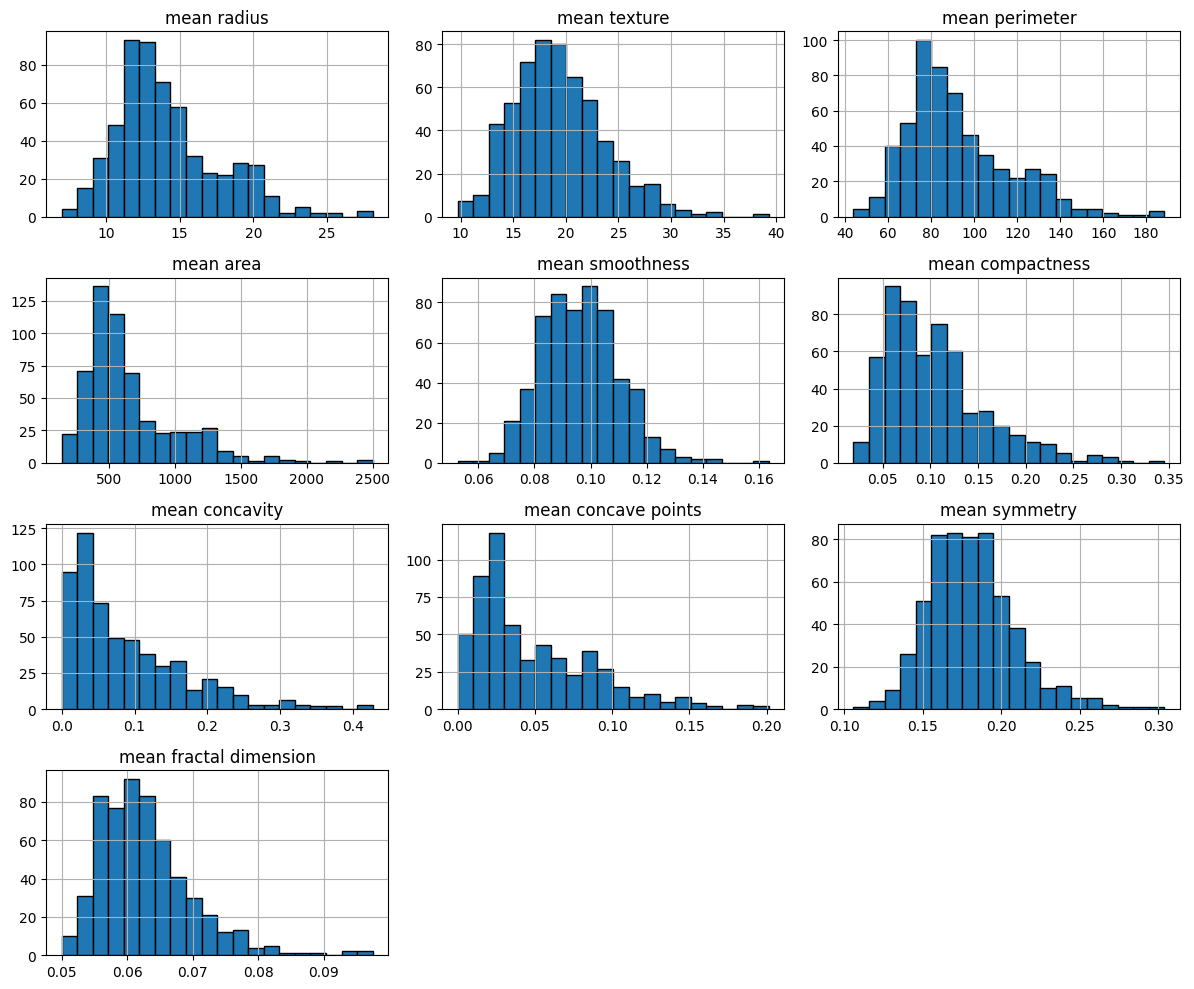

In [15]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)
df.filter(like="mean").hist(figsize=(12, 10), bins=20, edgecolor="black")
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

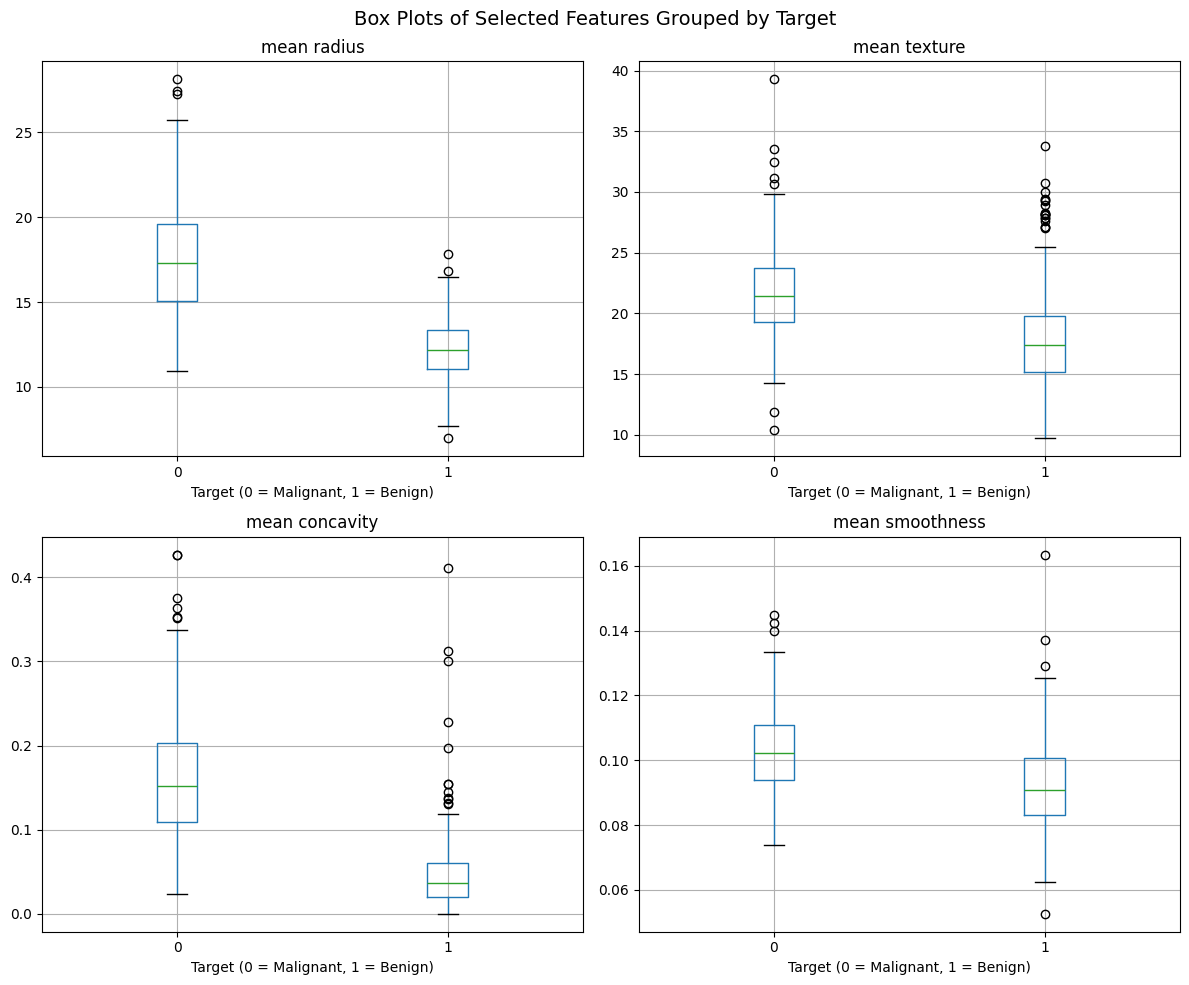

In [16]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
# TODO: one box plot per feature, grouped by target
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    df.boxplot(column=col, by="target", ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("Target (0 = Malignant, 1 = Benign)")

plt.suptitle("Box Plots of Selected Features Grouped by Target", fontsize=14)
plt.tight_layout()
plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

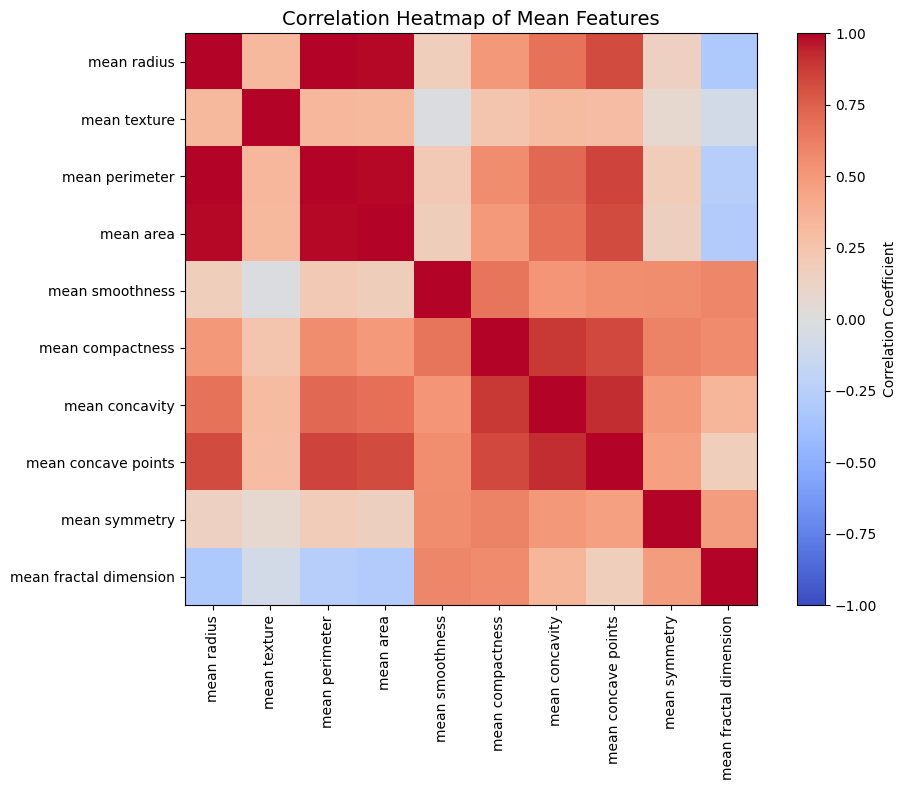

In [17]:
# TODO: correlation matrix of the "mean" features drawn with imshow
mean_corr = df.filter(like="mean").corr()

plt.figure(figsize=(10, 8))
plt.imshow(mean_corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation Coefficient")

plt.xticks(range(len(mean_corr.columns)), mean_corr.columns, rotation=90)
plt.yticks(range(len(mean_corr.columns)), mean_corr.columns)
plt.title("Correlation Heatmap of Mean Features", fontsize=14)
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

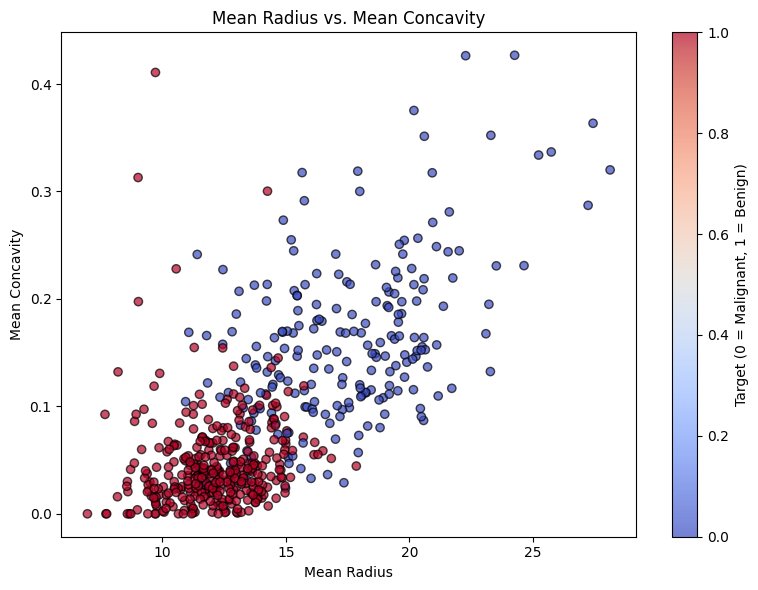

In [18]:
# TODO: coloured scatter plot with axis labels and a colourbar
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df["mean radius"],
    df["mean concavity"],
    c=df["target"],
    cmap="coolwarm",
    alpha=0.7,
    edgecolor="k",
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Concavity")
plt.title("Mean Radius vs. Mean Concavity")
cbar = plt.colorbar(scatter)
cbar.set_label("Target (0 = Malignant, 1 = Benign)")

plt.tight_layout()
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?


**ANSWER**: The mean radius, mean perimeter, and mean area are the features that are redundant because perimeter and area are calculated directly from the radius. On the other hand, mean concavity and mean concave points separate malignant and benign tumors most clearly, showing distinct groupings with minimal overlap in box plots and scatter plots.

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [19]:
# TODO: total missing values and duplicated rows
print("Missing values per column:\n", df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

X = df.drop(columns="target")
y = df["target"]

Missing values per column:
 mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

Total missing values: 0
Duplicate rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [20]:
# TODO: IQR outlier count per feature
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

# Identify outliers outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR]
outliers = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).sum()
top_10_outliers = outliers.sort_values(ascending=False).head(10)

print("Top 10 features with the most outliers:")
print(top_10_outliers)

Top 10 features with the most outliers:
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.


**ANSWER:** No, I will not delete outlying rows. Removing these records would risk losing critical clinical signals and skewing the model's ability to detect aggressive tumors. Instead, using robust scalers or tree-based algorithms is preferred to handle extreme values gracefully.

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [24]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95

corr_matrix = X.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.95)]
print("Features to drop due to high correlation (>0.95):", to_drop)

Features to drop due to high correlation (>0.95): ['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [25]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores

selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y)

kbest_scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
kbest_features = list(kbest_scores.head(10).index)

print("Top 10 features selected by SelectKBest:")
print(kbest_scores.head(10))

Top 10 features selected by SelectKBest:
worst concave points    964.385393
worst perimeter         897.944219
mean concave points     861.676020
worst radius            860.781707
mean perimeter          697.235272
worst area              661.600206
mean radius             646.981021
mean area               573.060747
mean concavity          533.793126
worst concavity         436.691939
dtype: float64


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [26]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

rfe = RFE(estimator=LogisticRegression(random_state=7), n_features_to_select=10)
rfe.fit(X_scaled, y)

rfe_features = list(X.columns[rfe.support_])
print("10 features selected by RFE:")
print(rfe_features)

10 features selected by RFE:
['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

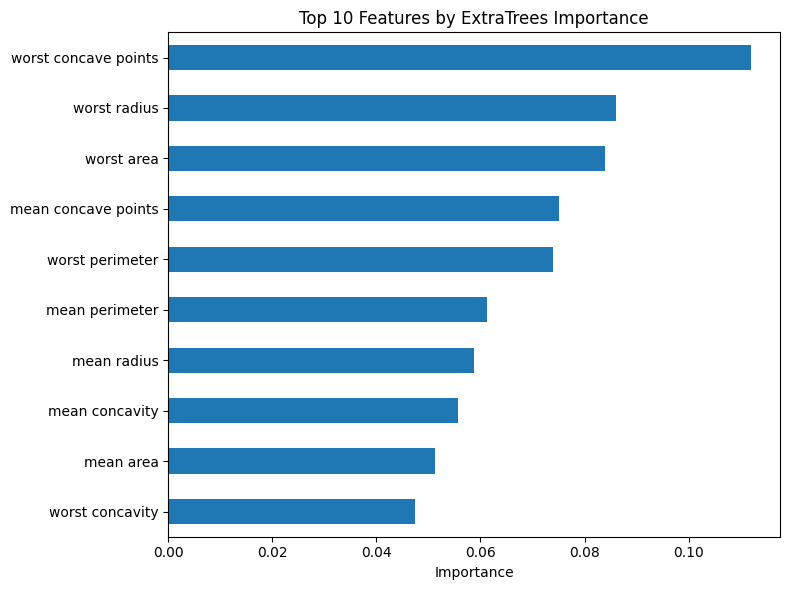

In [27]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10

et_model = ExtraTreesClassifier(n_estimators=200, random_state=7)
et_model.fit(X, y)

et_imp = pd.Series(et_model.feature_importances_, index=X.columns).sort_values(ascending=True)

# Plot top 10
plt.figure(figsize=(8, 6))
et_imp.tail(10).plot(kind="barh")
plt.title("Top 10 Features by ExtraTrees Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

extratrees_features = list(et_imp.tail(10).index)

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [28]:
# TODO: vote across the three methods
from collections import Counter

all_votes = kbest_features + rfe_features + extratrees_features
feature_counts = Counter(all_votes)

selected = [feature for feature, count in feature_counts.items() if count >= 2]
print(f"Selected {len(selected)} features chosen by at least 2 methods:")
print(selected)

Selected 10 features chosen by at least 2 methods:
['worst concave points', 'worst perimeter', 'mean concave points', 'worst radius', 'mean perimeter', 'worst area', 'mean radius', 'mean area', 'mean concavity', 'worst concavity']


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [32]:
# TODO: train_test_split with stratify=y

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=7
)

print("X_train shape:", X_train.shape, ", X_test shape:", X_test.shape)

X_train shape: (455, 30) , X_test shape: (114, 30)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [30]:
# TODO: fit both scalers on X_train and print the verifying statistics

std_scaler = StandardScaler().fit(X_train)
minmax_scaler = MinMaxScaler().fit(X_train)

X_train_std = std_scaler.transform(X_train)
X_train_minmax = minmax_scaler.transform(X_train)

# Print verifying statistics for the first 4 features
print("StandardScaler - First 4 features Mean:", np.round(X_train_std[:, :4].mean(axis=0), 4))
print("StandardScaler - First 4 features Std:", np.round(X_train_std[:, :4].std(axis=0), 4))
print("\nMinMaxScaler - First 4 features Min:", np.round(X_train_minmax[:, :4].min(axis=0), 4))
print("MinMaxScaler - First 4 features Max:", np.round(X_train_minmax[:, :4].max(axis=0), 4))

StandardScaler - First 4 features Mean: [ 0. -0. -0. -0.]
StandardScaler - First 4 features Std: [1. 1. 1. 1.]

MinMaxScaler - First 4 features Min: [0. 0. 0. 0.]
MinMaxScaler - First 4 features Max: [1. 1. 1. 1.]


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [33]:
# TODO: fit PCA on standardised training data and use the cumulative explained variance

pca = PCA().fit(X_train_std)
cum_var = np.cumsum(pca.explained_variance_ratio_)

n_components_95 = np.argmax(cum_var >= 0.95) + 1
print(f"Number of principal components explaining >= 95% variance: {n_components_95}")

Number of principal components explaining >= 95% variance: 10


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [37]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# Dictionary of candidate models
models = {
    "LR": LogisticRegression(random_state=seed),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC(random_state=seed),
}


def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = (
            [("scale", StandardScaler())] if scale else []
        ) + [("model", model)]
        results[name] = cross_val_score(
            Pipeline(steps), X_tr, y_train, cv=kfold, scoring="accuracy"
        )
    return results

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [38]:
# TODO: call spot_check twice and build a DataFrame called summary with columns raw / scaled
raw_results = spot_check(models, X_train, scale=False)
scaled_results = spot_check(models, X_train, scale=True)

# Build summary DataFrame
summary = pd.DataFrame(
    {
        "raw": {name: scores.mean() for name, scores in raw_results.items()},
        "scaled": {
            name: scores.mean() for name, scores in scaled_results.items()
        },
    }
)

display(summary)

,raw,scaled
LR,0.938357,0.982319
LDA,0.947246,0.947246
KNN,0.922947,0.964928
CART,0.927633,0.927633
NB,0.934058,0.932029
SVM,0.898696,0.975797


✏️ **Question D.3.** Which models benefit from scaling, and why?


**ANSWER:** KNN and SVM benefit the most from feature scaling. KNN relies on Euclidean distance calculations, and SVM calculates margin distances between data points; without scaling, features with larger numeric ranges (e.g., area and perimeter) completely dominate these distance metrics. Distance-free models like Decision Trees (CART) remain unaffected by scaling.

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [39]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results
selected_results = spot_check(models, X_train[selected], scale=True)

# Compare with all-features scaled
summary["selected_scaled"] = {
    name: scores.mean() for name, scores in selected_results.items()
}
display(summary)

,raw,scaled,selected_scaled
LR,0.938357,0.982319,0.960435
LDA,0.947246,0.947246,0.942995
KNN,0.922947,0.964928,0.942802
CART,0.927633,0.927633,0.925266
NB,0.934058,0.932029,0.951691
SVM,0.898696,0.975797,0.953865


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

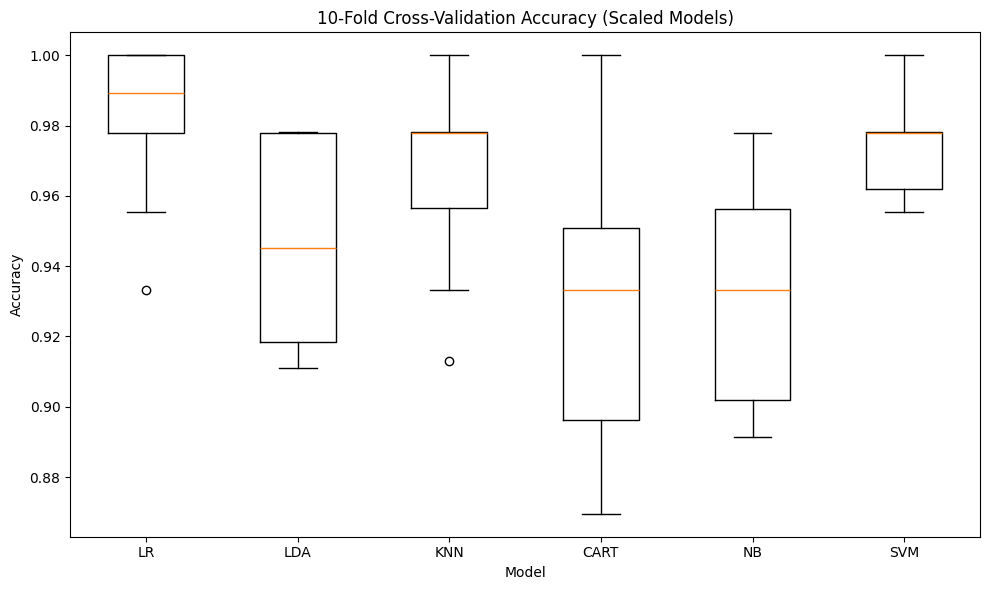

In [40]:
# TODO: box plot of the 10 fold scores per model
plt.figure(figsize=(10, 6))
plt.boxplot(
    [scaled_results[name] for name in models.keys()], labels=models.keys()
)
plt.title("10-Fold Cross-Validation Accuracy (Scaled Models)")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [41]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)

scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "recall_malignant": make_scorer(recall_score, pos_label=0),
}

# Pipeline for best scaled model (SVM)
best_model_pipeline = Pipeline(
    [("scale", StandardScaler()), ("model", SVC(random_state=seed))]
)

cv_results = cross_validate(
    best_model_pipeline, X_train, y_train, cv=kfold, scoring=scoring
)

print(
    f"Mean Accuracy:         {cv_results['test_accuracy'].mean():.4f}"
)
print(
    f"Mean ROC-AUC:          {cv_results['test_roc_auc'].mean():.4f}"
)
print(
    f"Mean Malignant Recall: {cv_results['test_recall_malignant'].mean():.4f}"
)

Mean Accuracy:         0.9758
Mean ROC-AUC:          0.9930
Mean Malignant Recall: 0.9588


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [42]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]

pipe_svm = Pipeline([("scale", StandardScaler()), ("model", SVC(random_state=seed))])

param_grid_svm = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.001, 0.01, 0.1],
    "model__kernel": ["rbf", "linear"],
}

grid_svm = GridSearchCV(
    pipe_svm, param_grid_svm, cv=kfold, scoring="accuracy", n_jobs=-1
)
grid_svm.fit(X_train, y_train)

print("Best SVM Parameters:", grid_svm.best_params_)
print(f"Best SVM CV Accuracy: {grid_svm.best_score_:.4f}")

Best SVM Parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best SVM CV Accuracy: 0.9802


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [43]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]

pipe_knn = Pipeline([("scale", StandardScaler()), ("model", KNeighborsClassifier())])

param_grid_knn = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"],
}

grid_knn = GridSearchCV(
    pipe_knn, param_grid_knn, cv=kfold, scoring="accuracy", n_jobs=-1
)
grid_knn.fit(X_train, y_train)

print("Best KNN Parameters:", grid_knn.best_params_)
print(f"Best KNN CV Accuracy: {grid_knn.best_score_:.4f}")

Best KNN Parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Best KNN CV Accuracy: 0.9693


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [44]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier

ensembles = {
    "RF": RandomForestClassifier(random_state=seed),
    "ET": ExtraTreesClassifier(random_state=seed),
    "GBM": GradientBoostingClassifier(random_state=seed),
    "AB": AdaBoostClassifier(random_state=seed),
}

# Score tree-based ensembles on raw training data
ensemble_results = spot_check(ensembles, X_train, scale=False)

# Build a hard VotingClassifier combining tuned SVM, tuned KNN, and Random Forest
voting_model = VotingClassifier(
    estimators=[
        ("tuned_svm", grid_svm.best_estimator_),
        ("tuned_knn", grid_knn.best_estimator_),
        ("rf", RandomForestClassifier(random_state=seed)),
    ],
    voting="hard",
)

voting_scores = cross_val_score(voting_model, X_train, y_train, cv=kfold, scoring="accuracy")
print(f"Voting Classifier CV Accuracy: {voting_scores.mean():.4f}")

Voting Classifier CV Accuracy: 0.9781


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [45]:
# TODO: leaderboard Series
leaderboard_dict = {
    "Tuned SVM": grid_svm.best_score_,
    "Tuned KNN": grid_knn.best_score_,
    "Voting Classifier": voting_scores.mean(),
}

for name, scores in ensemble_results.items():
    leaderboard_dict[name] = scores.mean()

leaderboard = pd.Series(leaderboard_dict).sort_values(ascending=False)
print("=== Model Leaderboard (CV Accuracy) ===")
print(leaderboard)

=== Model Leaderboard (CV Accuracy) ===
Tuned SVM            0.980193
Voting Classifier    0.978068
ET                   0.973575
Tuned KNN            0.969275
RF                   0.969130
GBM                  0.966957
AB                   0.962560
dtype: float64


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Test Accuracy: 0.9649

Classification Report:
               precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        42
      benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



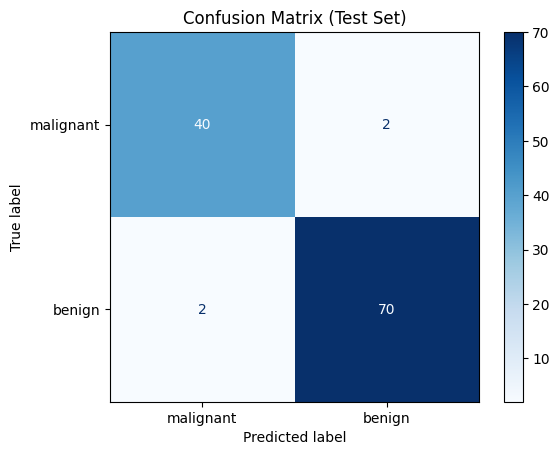

In [47]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix

import joblib
winner = grid_svm.best_estimator_
winner.fit(X_train, y_train)
y_pred = winner.predict(X_test)

print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:\n", classification_report(y_test, y_pred, target_names=data.target_names))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=data.target_names, cmap="Blues"
)
plt.title("Confusion Matrix (Test Set)")
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [48]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test

joblib.dump(winner, "best_breast_cancer_model.pkl")
loaded_model = joblib.load("best_breast_cancer_model.pkl")


reloaded_preds = loaded_model.predict(X_test)
print("Original first 5 predictions:", y_pred[:5])
print("Reloaded first 5 predictions:", reloaded_preds[:5])
print("Predictions match perfectly:", np.array_equal(y_pred, reloaded_preds))

Original first 5 predictions: [0 0 1 0 1]
Reloaded first 5 predictions: [0 0 1 0 1]
Predictions match perfectly: True


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.
2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?
3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)
4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?
5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.

**1. Leakage. Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a Pipeline.**

**ANSWER:**

Running feature selection on the whole dataset before splitting lets test data cheat into training, making models look unrealistically accurate. Putting feature selection inside a Pipeline ensures feature selection is fitted strictly on the training folds during each cross-validation split, preventing data leakage.

**2. Metric choice. Which metric would you report to a clinician, and why is accuracy alone insufficient?**

**ANSWER:**

I would report Recall (Sensitivity) for malignant cases alongside ROC-AUC. Recall measures how many cancers were correctly caught, which is critical because a false negative (missing cancer) is far more dangerous than a false positive.

**3. Model choice. If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)**

**ANSWER:**

I would pick the simpler, more interpretable model with higher malignant recall and stable results across folds. A small 0.3% accuracy difference isn't worth using a complex model if it misses more cancer cases.

**4. Generalization. How would your conclusions change with a much smaller or much more imbalanced dataset?**

**ANSWER:**

A smaller dataset risks overfitting, so I would prefer simpler models with stronger regularization. A highly imbalanced dataset makes accuracy useless, requiring class-weight adjustments, oversampling (SMOTE), and metrics like Recall or PR-AUC.

**5. Extension. Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.**

**ANSWER:**

 --